# BranchSync

Reproduce the balanced ToySplit branching experiment behind Figure 2b. The primary space
contains only weak branch separation, while the paired secondary space amplifies the split.
The observations are generated directly from the original seed-42 recipe, assembled as
AnnData, and used to refit a time-conditioned map before training the two vector fields.
The map is refitted with the original raw-coordinate FiLM architecture, split, loss,
optimizer and Sinkhorn checkpoint-selection rule; no legacy checkpoint is loaded.

This notebook compares the balanced RNA-only control with balanced synchronized COATI.
The historical unbalanced beta sweep is documented at the end but is not mixed into this
BranchSync result.

In [1]:
from pathlib import Path
import sys
import uuid

example_dir = next(parent / "examples" for parent in (Path.cwd(), *Path.cwd().parents)
                   if (parent / "examples" / "synthetic" / "branch_sync.py").is_file())
if str(example_dir) not in sys.path:
    sys.path.insert(0, str(example_dir))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import coati as ct
from synthetic.branch_sync import (
    TIME_POINTS,
    make_anndata,
    evaluate_map,
    train_historical_map,
    plot_data_and_map,
    plot_branch_comparison,
    branch_diagnostics,
)
from synthetic.gaussian_comparison import make_shared_initial_checkpoint

%matplotlib inline
torch.set_num_threads(1)
plt.rcParams.update({"font.family": "Arial", "font.size": 11})
run_dir = Path("outputs") / ("branch-sync-" + uuid.uuid4().hex[:8])
run_dir.mkdir(parents=True)
print("Result directory:", run_dir)

Result directory: outputs/branch-sync-8b14568c


## Generate the paired snapshots

The spatial coordinate uses five adjacent bins on $[0,1]$. COATI training time is kept on
the historical $0,1,2,3,4$ grid. Each snapshot contains 400 paired cells in the same row
order. These spatial bins and model times are distinct quantities.

In [2]:
cells = make_anndata(n_per_time=400, seed=42)
data = ct.TemporalData.from_anndata(
    cells, obsm_key="X_latent", secondary_obsm_key="X_secondary"
)
summary = cells.obs.groupby(["time", "celltype"], observed=True).size().rename("Cells").to_frame()
assert data.times.tolist() == TIME_POINTS.tolist()
assert [len(snapshot) for snapshot in data.primary] == [400] * 5
summary

Cells
time celltype       
0.0  shared      400
1.0  lower       200
     upper       200
2.0  branch_A    200
     branch_B    200
3.0  branch_A    200
     branch_B    200
4.0  branch_A    200
     branch_B    200

## Fit and inspect the cross-modal map

The map follows the original three-layer FiLM architecture with width 64 and a
32-dimensional time embedding. It is trained on raw coordinates with no feature or time
standardization. Twenty percent of each stage is withheld; every fifth epoch is ranked by
the sum of per-stage validation Sinkhorn divergences.

In [3]:
T, map_report = train_historical_map(cells, run_dir / "map", seed=0)
validation_scores = pd.DataFrame(map_report["stages"]).set_index("time")[
    ["validation_cells", "paired_rmse", "r2", "sinkhorn"]
]
map_scores = evaluate_map(cells, T)
print("Selected map epoch:", map_report["best_epoch"])
display(validation_scores.round(6))
map_scores.round(6)

Selected map epoch: 295


,validation_cells,paired_rmse,r2,sinkhorn
time,,,,
0.0,80,0.002397,0.996650,0.000006
1.0,80,0.016145,0.919880,0.000112
2.0,80,0.017249,0.954185,0.000161
3.0,80,0.023427,0.937998,0.000393
4.0,80,0.027798,0.925834,0.000607


,Pairs,RMSE,R2
Time,,,
0.0,400,0.002467,0.996879
1.0,400,0.017010,0.911787
2.0,400,0.015650,0.962201
3.0,400,0.021392,0.947993
4.0,400,0.026780,0.934251


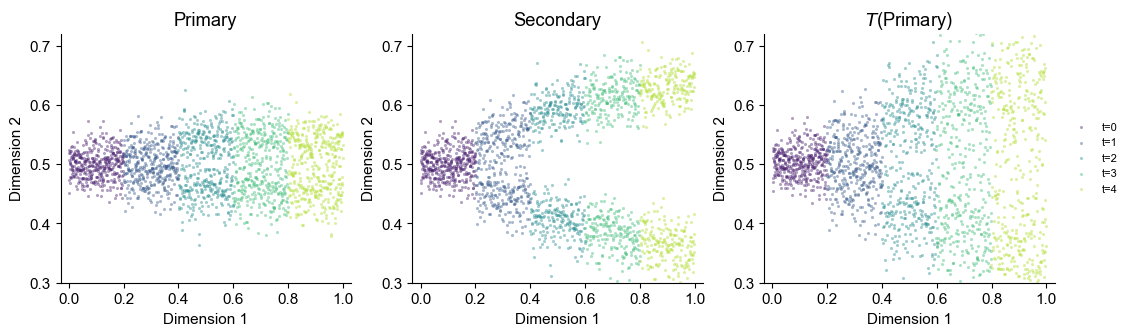

In [4]:
plot_data_and_map(cells, T);

## Configure the balanced comparison

Both vector fields use the Figure 2b architecture and training budget: width 256, two
LeakyReLU layers, batch size 128 and 5,000 iterations. The synchronized model uses
$C_y=0.5$ and density coefficient 10; the RNA-only control uses density coefficient 1.
The RNA-only control uses primary PDF coefficient 100. BranchSync uses primary PDF
coefficient 0.1 and secondary PDF coefficient 100. The kinetic-energy
weight is 0.1.

In [5]:
adaptive_base = {
    "adaptive_lambda": True,
    "median_n_sample": 128,
    "floor_n_sample": 128,
    "floor_buffer_std": 1.0,
    "lambda_min": 1.0,
    "eta_lambda": 1.0,
    "lambda_min_pri": 1.0,
    "lambda_min_sec": 1.0,
    "eta_lambda_pri": 1.0,
    "eta_lambda_sec": 1.0,
    "dual_warmup": 1000,
    "dual_decay": 1.0,
    "dual_update_freq": 10,
    "dual_ema_alpha": 0.1,
    "lambda_update_mode": "max",
    "eta_neg_scale": 100.0,
}
control_adaptive = {**adaptive_base,
    "pdf_coefficient_sec": 100.0,
    "lambda_init": 100.0, "lambda_min": 100.0, "lambda_max": 100.0,
    "lambda_init_pri": 100.0, "lambda_min_pri": 100.0, "lambda_max_pri": 100.0,
    "lambda_init_sec": 100.0, "lambda_min_sec": 100.0, "lambda_max_sec": 100.0,
}
sync_adaptive = {**adaptive_base,
    "pdf_coefficient_sec": 100.0,
    "lambda_init": 0.1, "lambda_min": 0.1, "lambda_max": 0.1,
    "lambda_init_pri": 0.1, "lambda_min_pri": 0.1, "lambda_max_pri": 0.1,
    "lambda_init_sec": 100.0, "lambda_min_sec": 100.0, "lambda_max_sec": 100.0,
}
common = dict(
    balanced=True,
    iterations=5_000,
    batch_size=128,
    hidden_dim=256,
    n_layers=2,
    activation="leaky_relu",
    learning_rate=1e-3,
    energy_weight=.1,
    seed=0,
)
configs = {
    "OT (primary only)": ct.Config(multimodal=False, manifold_weight=1.,
                                     matching_weight=100., extra=control_adaptive, **common),
    "BranchSync": ct.Config(multimodal=True, secondary_weight=.5,
                            manifold_weight=10., matching_weight=.1,
                            extra=sync_adaptive, **common),
}
pd.DataFrame({name: {key: cfg.to_dict()[key] for key in
    ["niters", "num_samples", "hidden_dim", "sync_loss", "sync_weight",
     "energy_coefficient", "pdf_coefficient", "density_coefficient"]}
    for name, cfg in configs.items()})

,OT (primary only),BranchSync
niters,5000,5000
num_samples,128,128
hidden_dim,256,256
sync_loss,False,True
sync_weight,0.0,0.5
energy_coefficient,0.1,0.1
pdf_coefficient,100.0,0.1
density_coefficient,1.0,10.0


## Train from the same initialization

The two runs start from one common weight-only checkpoint. The synchronized run receives
the frozen fitted map; the control sees only the primary snapshots.

In [6]:
initial = make_shared_initial_checkpoint(
    configs["OT (primary only)"], run_dir / "initial.pt"
)
results = {}
for name, config in configs.items():
    print("Training:", name, flush=True)
    slug = "primary-only" if not config.multimodal else "branch-sync"
    results[name] = ct.fit(
        data,
        config,
        output_dir=run_dir / slug,
        T_model=T if config.multimodal else None,
        warm_start_path=initial,
    )

Training: OT (primary only)


Training: BranchSync


## Compare the learned branches

All 400 initial particles are integrated on the historical 0–4 grid. Thin lines show a
fixed display subset; the two thick lines summarize the upper and lower distribution halves. The same
frozen map is applied to both primary trajectories for a direct secondary-space comparison.

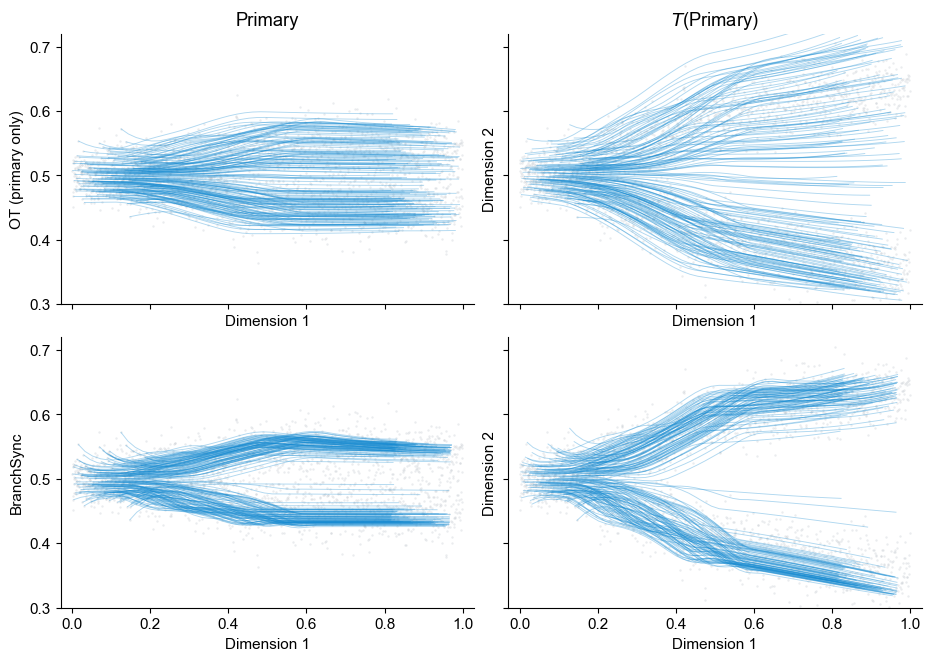

In [7]:
prediction_times = np.linspace(0., 4., 41)
predictions = {
    name: result.predict(times=prediction_times, method="rk4")
    for name, result in results.items()
}
plot_branch_comparison(cells, T, results, predictions);

In [8]:
separation = branch_diagnostics(cells, T, results, predictions)
endpoint = pd.DataFrame({name: result.evaluate() for name, result in results.items()}).T
display(separation.round(6))
endpoint[["endpoint_sinkhorn_after", "kinetic_energy_mean"]].round(6)

,Primary terminal separation,Mapped terminal separation,Secondary endpoint Sinkhorn
Model,,,
OT (primary only),0.091543,0.253369,0.000428
BranchSync,0.098697,0.273056,0.000206


,endpoint_sinkhorn_after,kinetic_energy_mean
OT (primary only),0.000026,0.080526
BranchSync,0.000087,0.079932
